# 02. 저장 노드 접합 누설 (D2, DEVSIM 소자 시뮬레이션)

01에서는 누설 전류를 "2.5 fA"라는 **가정값**으로 두었습니다. 이 노트북에서는 그 누설이 어디서 오는지를
소자 시뮬레이터(DEVSIM)로 **직접 계산**합니다. 현업에서 TCAD로 하는 단계에 해당합니다.

**실행 방법**: 메뉴에서 **런타임 → 모두 실행**. 기준 설계안 결과는 미리 계산해 두었고, 설계안을 바꿨다면 약 5초 동안 다시 계산합니다.

> 모든 수치는 가정한 구조와 파라미터로 계산한 시뮬레이션입니다. 실제 제품 값이 아닙니다.

In [1]:
import os, sys, subprocess
BRANCH = "claude/feature-research"
REPO_URL = "https://github.com/tjrgns1753-create/dsadsa"
REPO_DIR = "/content/dsadsa"


def _sync_repo(repo_dir, url, branch):
    """저장소를 내려받거나 최신으로 맞춘다. 갱신에 실패해도 멈추지 않고 기존 코드로 계속한다."""
    if not os.path.isdir(repo_dir):
        subprocess.run(["git", "clone", "-q", "--depth", "1", "-b", branch, url, repo_dir], check=True)
        return
    for cmd in (["git", "-C", repo_dir, "fetch", "-q", "--depth", "1", "origin", branch],
                ["git", "-C", repo_dir, "reset", "-q", "--hard", "FETCH_HEAD"]):
        if subprocess.run(cmd, capture_output=True).returncode != 0:
            print("경고: 최신 코드로 갱신하지 못해 기존 코드로 계속합니다 (" + " ".join(cmd[3:5]) + ")")
            return


if "google.colab" in sys.modules:
    _sync_repo(REPO_DIR, REPO_URL, BRANCH)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", REPO_DIR], check=True)
    if REPO_DIR not in sys.path:
        sys.path.insert(0, REPO_DIR)
    for _m in [m for m in sys.modules if m == "memdev" or m.startswith("memdev.")]:
        del sys.modules[_m]  # 갱신된 코드를 다시 불러오도록 이전에 불러온 모듈을 지운다
from memdev.colab import setup
status = setup(install=True)
print(status)

{'ngspice': True, 'devsim': True, 'korean_font': True}


## 1. 무엇을 계산하나

DRAM 셀의 커패시터는 **n+ 영역(저장 노드)** 을 통해 트랜지스터에 붙어 있고, 그 아래는 **p형 웰**입니다.
즉 저장 노드는 **n+/p 접합(다이오드)** 입니다.

- 셀에 '1'(Vdd)을 저장하면 n+ 쪽이 p 웰보다 전압이 높아 이 다이오드에 **역방향 전압**이 걸립니다.
- 역방향 다이오드에도 아주 작은 전류가 흐르고, 이것이 커패시터의 전하를 빼 가는 **접합 누설**입니다.

역방향 누설은 크게 두 가지입니다.

| 성분 | 원리 | 온도 민감도 |
|---|---|---|
| **생성 전류** | 공핍층 안의 트랩(결함)을 거쳐 전자-정공 쌍이 생겨 전계에 끌려감 (SRH 생성) | n_i에 비례 → 활성화 에너지 ≈ Eg/2 ≈ 0.56 eV |
| **확산 전류** | 공핍층 밖에서 소수 캐리어가 공핍층으로 확산해 들어옴 | n_i²에 비례 → 활성화 에너지 ≈ Eg ≈ 1.12 eV |

SRH 생성률: $U = \dfrac{np - n_i^2}{\tau_p(n+n_1) + \tau_n(p+p_1)}$. 공핍층에서는 n, p가 매우 작아 $U \approx -n_i/(2\tau)$, 즉 **생성**이 됩니다.
캐리어 수명 τ가 짧을수록(트랩이 많을수록) 누설이 큽니다.

**왜 공식만으로 안 하고 시뮬레이터를 쓰나**: 공식 $J \approx q n_i W / (2\tau)$는 공핍층 전체에서 생성이 최대라고 가정한 **상한**입니다.
실제로는 공핍층 가장자리에서 생성이 줄고, 확산 성분이 더해지고, 전압·도핑에 따라 둘의 비중이 바뀝니다. 시뮬레이터는 포아송 방정식과
전자·정공 연속 방정식을 격자 위에서 함께 풀어 이걸 직접 계산합니다.

**구조 (1차원)**: 위쪽 0.5 µm는 n+ 저장 노드(도핑 ND), 아래쪽 0.5 µm는 p 웰(도핑 NA), 급격한 접합. 위쪽에 역방향 전압 V_R을 겁니다.

**시뮬레이션하면서 잡은 두 가지 함정** (면접에서 말할 거리)
1. DEVSIM 기본 모델은 진성 캐리어 농도 n_i를 온도와 무관한 상수로 둡니다. 그대로 쓰면 온도를 바꿔도 누설이 안 변하므로 n_i(T)를 직접 넣었습니다.
2. 단자 전류를 그대로 읽으면, 도핑이 높은 쪽에서 큰 드리프트·확산 전류가 서로 상쇄되면서 컴퓨터의 소수점 정밀도 오차가 10⁻⁹ A/cm² 수준의 누설을 덮어 버립니다.
   그래서 **정밀도가 좋은 성분만** 더했습니다: 소자 안의 생성률 적분 + 양쪽 단자의 소수 캐리어 전류.

In [2]:
import matplotlib.pyplot as plt
import numpy as np

from memdev.design import design_table, load_design
from memdev.dram.d2 import D2_REF, run_d2_sweep
from memdev.plotting import plain_log_ticks, sim_label
from memdev.results import ResultMissing, load_result, save_result
from memdev.silicon import bandgap_ev, generation_bound
from memdev.units import K_B_EV

DESIGN = load_design()
P = DESIGN.values()
print(f"사용 중인 설계안: {DESIGN.name} (기준값에서 바꾼 항목: {list(DESIGN.overrides) or '없음'})")
try:
    result = load_result("D2", DESIGN)
    print(f"D2 결과를 불러왔습니다 ({'미리 계산한 기준 결과' if result.source == 'precomputed' else '이 런타임에서 계산한 결과'}).")
    D2 = result.data
except ResultMissing as e:
    print(e)
    print("지금 계산합니다 (약 5초)...")
    D2 = run_d2_sweep(DESIGN)
    save_result("D2", DESIGN, D2)
    print("계산을 마치고 결과를 저장했습니다.")

TEMPS, BIASES = D2["temps_c"], D2["biases_v"]
J = np.array(D2["j_total"])
JG, JD = np.array(D2["j_gen"]), np.array(D2["j_diff"])
I_REF_T, I_REF_V = TEMPS.index(D2_REF["temp_c"]), BIASES.index(D2_REF["bias_v"])
LABEL = sim_label(f"설계안 {DESIGN.name}")

사용 중인 설계안: baseline (기준값에서 바꾼 항목: 없음)
D2 결과를 불러왔습니다 (미리 계산한 기준 결과).


## 2. 역방향 전압과 온도에 따른 누설

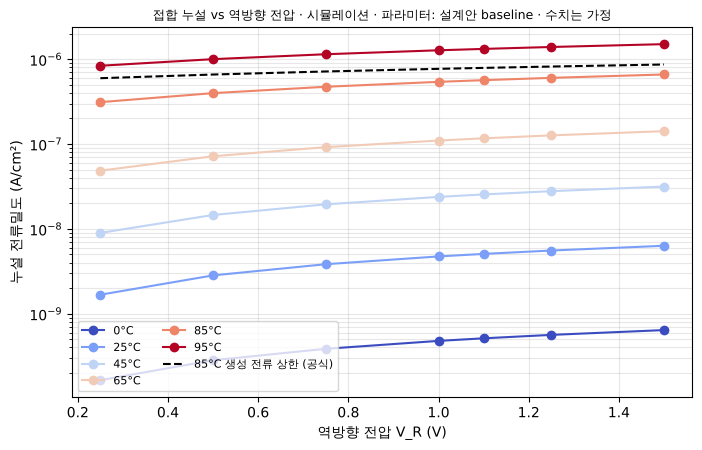

In [3]:
colors = plt.cm.coolwarm(np.linspace(0, 1, len(TEMPS)))
fig, ax = plt.subplots(figsize=(8, 4.8))
for t, row, c in zip(TEMPS, J, colors):
    ax.semilogy(BIASES[1:], row[1:], "o-", color=c, label=f"{t:g}°C")
bound = [generation_bound(D2_REF["temp_c"], P["na"], P["nd"], P["tau_srh"], v) for v in BIASES[1:]]
ax.semilogy(BIASES[1:], bound, "k--", label="85°C 생성 전류 상한 (공식)")
ax.set_xlabel("역방향 전압 V_R (V)")
ax.set_ylabel("누설 전류밀도 (A/cm²)")
ax.set_title("접합 누설 vs 역방향 전압 · " + LABEL, fontsize=9)
ax.legend(fontsize=8, ncol=2)
ax.grid(alpha=0.3, which="both")
plt.show()

**읽는 법**
- 전압이 오르면 공핍층이 넓어져(W ∝ √(Vbi+V_R)) 생성 전류가 완만하게 늘어납니다.
- 온도가 오르면 같은 전압에서 누설이 자릿수로 늘어납니다.
- 점선(공식 상한)보다 시뮬레이션이 아래에 있습니다. 공식은 공핍층 전체에서 생성이 최대라고 가정하기 때문이고, 전압이 클수록 둘이 가까워집니다.
  (85°C 곡선에는 확산 성분도 들어 있어 상한과 직접 비교는 생성 성분으로 해야 합니다. 검증 테스트는 생성 성분으로 비교합니다.)

## 3. 온도: 어떤 메커니즘이 지배하나 (아레니우스 그림)

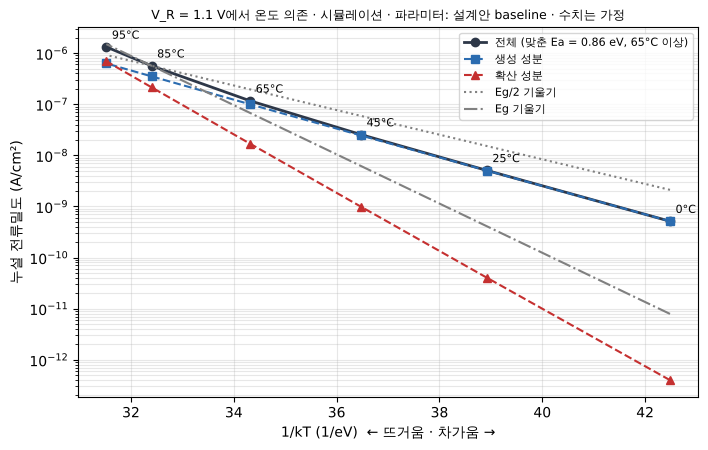

In [4]:
temps = np.array(TEMPS)
inv_kt = 1 / (K_B_EV * (temps + 273.15))
jt, jg, jd = J[:, I_REF_V], JG[:, I_REF_V], JD[:, I_REF_V]
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.semilogy(inv_kt, jt, "o-", color="#2d3748", lw=2, label=f"전체 (맞춘 Ea = {D2['ea_ev']:.2f} eV, 65°C 이상)")
ax.semilogy(inv_kt, jg, "s--", color="#2b6cb0", label="생성 성분")
ax.semilogy(inv_kt, jd, "^--", color="#c53030", label="확산 성분")
x0, y0 = inv_kt[I_REF_T], jt[I_REF_T]
for ea, style, name in ((bandgap_ev(85.0) / 2, ":", "Eg/2 기울기"), (bandgap_ev(85.0), "-.", "Eg 기울기")):
    ax.semilogy(inv_kt, y0 * np.exp(-ea * (inv_kt - x0)), style, color="gray", label=name)
for x, y, t in zip(inv_kt, jt, TEMPS):
    ax.annotate(f"{t:g}°C", (x, y), textcoords="offset points", xytext=(4, 6), fontsize=8)
ax.set_xlabel("1/kT (1/eV)  ← 뜨거움 · 차가움 →")
ax.set_ylabel("누설 전류밀도 (A/cm²)")
ax.set_title(f"V_R = {D2_REF['bias_v']} V에서 온도 의존 · " + LABEL, fontsize=9)
ax.legend(fontsize=8)
ax.grid(alpha=0.3, which="both")
plt.show()

**읽는 법**
- 가로축이 1/kT라서 아레니우스 법칙을 따르는 성분은 **직선**이 되고, 기울기가 활성화 에너지입니다.
- 생성 성분(파랑)은 Eg/2 기울기, 확산 성분(빨강)은 Eg 기울기를 따릅니다. 확산이 온도에 더 민감해서, **온도가 오를수록 확산 비중이 커지고**
  이 구조에서는 약 95°C에서 확산이 생성을 넘어섭니다.
- 그래서 전체 누설의 활성화 에너지는 두 값 사이(맞춘 값 위 범례)로 나옵니다. 01에서 가정한 0.6 eV는 생성 위주일 때의 값에 가깝습니다.
- 주의: 확산 성분의 크기는 p 영역 길이(단자까지 0.5 µm) 같은 **구조**에 따라 달라집니다.

## 4. 도핑과 캐리어 수명의 영향 (85°C, 1.1 V)

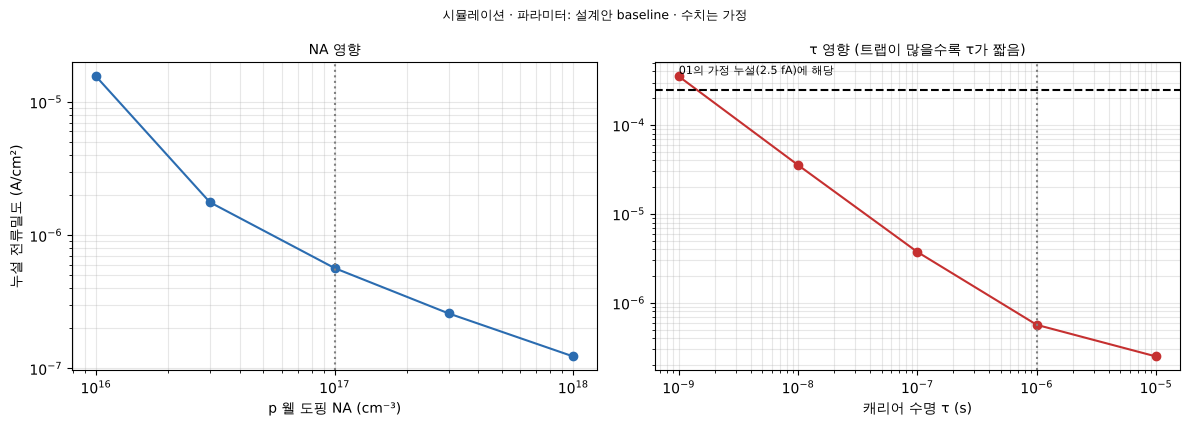

In [5]:
na_s, tau_s = D2["na_sweep"], D2["tau_sweep"]
j_needed = P["i_leak_ref"] / P["j_area"]  # 01의 가정 누설을 내려면 필요한 전류밀도
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.3))
ax1.loglog(na_s["na"], na_s["j_total"], "o-", color="#2b6cb0")
ax1.axvline(P["na"], ls=":", color="gray")
ax1.set_xlabel("p 웰 도핑 NA (cm⁻³)")
ax1.set_ylabel("누설 전류밀도 (A/cm²)")
ax1.set_title("NA 영향", fontsize=10)
ax1.grid(alpha=0.3, which="both")
ax2.loglog(tau_s["tau"], tau_s["j_total"], "o-", color="#c53030")
ax2.axhline(j_needed, ls="--", color="black")
ax2.text(tau_s["tau"][0], j_needed * 1.5, "01의 가정 누설(2.5 fA)에 해당", fontsize=8)
ax2.axvline(P["tau_srh"], ls=":", color="gray")
ax2.set_xlabel("캐리어 수명 τ (s)")
ax2.set_title("τ 영향 (트랩이 많을수록 τ가 짧음)", fontsize=10)
ax2.grid(alpha=0.3, which="both")
fig.suptitle(LABEL, fontsize=9)
fig.tight_layout()
plt.show()

**읽는 법**
- **τ**: 생성 전류는 1/τ에 비례합니다. 트랩(결함)이 많을수록 누설이 커지니, 공정에서 결함을 줄이는 것이 리텐션 개선의 핵심입니다.
- **NA**: 이 모델에서는 NA가 클수록 누설이 줄어듭니다(소수 캐리어 n_i²/NA와 공핍층 폭이 줄기 때문). **하지만 이건 모델의 한계 때문에 생긴 경향입니다.**
  실제 소자에서는 도핑이 높을수록 접합 전계가 세져서 **전계 강화·트랩 보조 터널링(TAT)** 누설이 급증합니다. 이 모델은 그 효과를 넣지 않았습니다.
  그래서 실제 DRAM은 저장 노드 접합의 도핑 경사를 완만하게 만들어 전계를 낮춥니다.

## 5. 셀 하나의 누설: 01의 가정과 비교

In [6]:
from IPython.display import Markdown, display

cell_fa = D2["cell_leak_a"] * 1e15
assumed_fa = P["i_leak_ref"] * 1e15
display(Markdown("\n".join([
    "| 항목 | 값 |", "|---|---|",
    f"| D2 계산 전류밀도 (85°C, 1.1 V) | {J[I_REF_T, I_REF_V]:.3g} A/cm² |",
    f"| 접합 면적 (가정) | {P['j_area']:.3g} cm² |",
    f"| **D2 계산 셀당 누설** | **{cell_fa:.3g} fA** |",
    f"| 01의 가정 누설 | {assumed_fa:.3g} fA |",
    f"| 차이 | 약 {assumed_fa / cell_fa:.0f}배 |",
])))

| 항목 | 값 |
|---|---|
| D2 계산 전류밀도 (85°C, 1.1 V) | 5.65e-07 A/cm² |
| 접합 면적 (가정) | 1e-11 cm² |
| **D2 계산 셀당 누설** | **0.00565 fA** |
| 01의 가정 누설 | 2.5 fA |
| 차이 | 약 442배 |

**이 차이가 말해 주는 것**
- 트랩을 통한 SRH 생성과 확산만으로 계산하면(τ = 1 µs) 누설이 01의 가정보다 **수백 배 작습니다.**
- 4절의 τ 그래프에서 검은 점선과 만나는 곳을 보면 τ가 **약 1 ns** 수준이어야 가정 누설이 나옵니다. 그만큼 결함이 많은 영역이거나,
- 이 모델에 없는 메커니즘이 실제 누설을 지배한다는 뜻입니다: 강한 전계에서의 **트랩 보조 터널링(TAT)**, 접근 트랜지스터의 **GIDL**과 서브스레숄드 누설.
- 이 차이를 어떻게 메울지(어떤 모델과 파라미터로 리텐션을 계산할지)는 **D3 모델 추출**에서 정합니다.

## 6. 직접 바꿔 보기 (DEVSIM을 바로 실행)
값을 바꾸면 DEVSIM이 한 번 계산합니다(약 0.2초). NA와 τ는 **[현재 설계안으로 저장]** 으로 설계안에 넣을 수 있고, 다음 단계가 그 값을 씁니다.

In [7]:
import ipywidgets as w

from memdev.dram.devsim_junction import JunctionSimError, simulate_junction
from memdev.widgets import design_save_panel

temp_w = w.IntSlider(value=85, min=0, max=95, step=5, description="온도 (°C)", continuous_update=False)
vr_w = w.FloatSlider(value=1.1, min=0.0, max=1.5, step=0.05, description="V_R (V)", continuous_update=False)
na_w = w.FloatLogSlider(value=P["na"], base=10, min=16, max=18, step=0.1, description="NA (cm⁻³)",
                        continuous_update=False)
tau_w = w.FloatLogSlider(value=P["tau_srh"], base=10, min=-10, max=-3, step=0.25, description="τ (s)",
                         continuous_update=False)


def junction(temp_c, vr, na, tau):
    try:
        r = simulate_junction(temp_c=temp_c, na=na, nd=P["nd"], tau=tau, biases_v=[vr])
    except JunctionSimError as e:
        print(e)
        return
    j, jg, jd = r.j_total[0], r.j_gen[0], r.j_diff[0]
    print(f"누설 전류밀도: {j:.3g} A/cm²  (생성 {jg:.3g}, 확산 {jd:.3g})")
    print(f"셀당 누설: {j * P['j_area'] * 1e15:.3g} fA  (접합 면적 {P['j_area']:.3g} cm²)")
    if vr > 0:
        print(f"생성 성분 / 공식 상한: {jg / generation_bound(temp_c, na, P['nd'], tau, vr):.2f}")


ui = w.interactive(junction, temp_c=temp_w, vr=vr_w, na=na_w, tau=tau_w)
display(ui, design_save_panel(lambda: {"na": na_w.value, "tau_srh": tau_w.value},
                              DESIGN.name if DESIGN.overrides else "my_design"))

interactive(children=(IntSlider(value=85, continuous_update=False, description='온도 (°C)', max=95, step=5), Flo…

## 7. 면접에서 이렇게 말할 수 있습니다

> "DRAM 저장 노드는 n+/p 접합이라 '1'을 저장하면 역방향 바이어스가 걸리고, 공핍층의 트랩을 통한 SRH 생성 전류와 중성 영역의 확산 전류가 누설이 됩니다.
> 생성은 n_i에, 확산은 n_i²에 비례해서 활성화 에너지가 각각 Eg/2, Eg 근처이고, 고온일수록 확산 비중이 커집니다.
> DEVSIM으로 1D 접합을 풀어 보니 τ = 1 µs의 SRH만으로는 셀당 누설이 fA보다 훨씬 작게 나왔고, 실제 수준을 설명하려면 짧은 수명이나 전계 강화 터널링, GIDL 같은 메커니즘이 필요하다는 걸 확인했습니다.
> 시뮬레이션 중에는 n_i의 온도 의존이 빠진 기본 모델과, 단자 전류의 수치 상쇄 오차 문제를 찾아 고쳤습니다."

## 8. 한계
- 1차원 급격 접합입니다. 실제 저장 노드는 3차원 구조이고 도핑이 경사져 있습니다.
- 전계 강화(Poole-Frenkel)·트랩 보조 터널링, 밴드 간 터널링을 넣지 않았습니다. 그래서 도핑이 높을 때의 누설을 과소평가합니다.
- 트랩은 밴드갭 한가운데 하나(n1 = p1 = n_i)이고 τn = τp로 같다고 두었습니다.
- 확산 성분은 단자까지의 거리(구조 길이)에 의존합니다.
- 모든 파라미터는 가정값입니다.

## 9. 사용한 설계안

In [8]:
def fmt(x):
    return f"{x:.3g}"


lines = [f"설계안 **{DESIGN.name}** · 굵은 글씨는 기준값에서 바꾼 항목", "",
         "| 항목 | 기준값 | 현재 설계안 | 단위 | 상태 | 출처 |", "|---|---|---|---|---|---|"]
for r in design_table(DESIGN):
    cur = f"**{fmt(r.current)}**" if r.changed else fmt(r.current)
    lines.append(f"| {r.key} | {fmt(r.base)} | {cur} | {r.unit} | {r.status} | {r.source} |")
display(Markdown("\n".join(lines)))

설계안 **baseline** · 굵은 글씨는 기준값에서 바꾼 항목

| 항목 | 기준값 | 현재 설계안 | 단위 | 상태 | 출처 |
|---|---|---|---|---|---|
| cs | 1e-14 | 1e-14 | F | assumed | 시험작 가정값, 공개 자료 확인 전 |
| cbl | 5e-14 | 5e-14 | F | assumed | 시험작 가정값, 공개 자료 확인 전 |
| vdd | 1.1 | 1.1 | V | assumed | 시험작 가정값, 공개 자료 확인 전 |
| sense_min | 0.05 | 0.05 | V | assumed | 시험작 가정값, 공개 자료 확인 전 |
| i_leak_ref | 2.5e-15 | 2.5e-15 | A | assumed | 시험작 가정값, 공개 자료 확인 전 (t_ref_c에서의 셀 누설) |
| t_ref_c | 85 | 85 | degC | assumed | 시험작 가정값, 공개 자료 확인 전 |
| ea | 0.6 | 0.6 | eV | assumed | 시험작 가정값, 공개 자료 확인 전 |
| t_refresh | 0.064 | 0.064 | s | assumed | 시험작 가정값, 공개 자료 확인 전 |
| write_pulse | 1e-08 | 1e-08 | s | assumed | 시험작 가정값, 공개 자료 확인 전 |
| repair_limit | 1e+03 | 1e+03 | cells | assumed | 근거 미확인 가정값, D6에서 민감도로 다룸 |
| na | 1e+17 | 1e+17 | cm^-3 | assumed | M2 가정값, 공개 자료 확인 전 (p 웰 억셉터 농도) |
| nd | 1e+19 | 1e+19 | cm^-3 | assumed | M2 가정값, 공개 자료 확인 전 (n+ 저장 노드 도너 농도) |
| tau_srh | 1e-06 | 1e-06 | s | assumed | M2 가정값, 공개 자료 확인 전 (SRH 캐리어 수명, 트랩 밀도의 대리 변수) |
| j_area | 1e-11 | 1e-11 | cm^2 | assumed | M2 가정값, 공개 자료 확인 전 (셀당 저장 노드 접합 면적) |